In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## EDA

In [2]:
#MTS Library
df = pd.read_csv('..\\data\\raw\\interactions.csv')

In [3]:
df

,user_id,item_id,progress,rating,start_date
0,126706,14433,80,NaN,2018-01-01
1,127290,140952,58,NaN,2018-01-01
2,66991,198453,89,NaN,2018-01-01
3,46791,83486,23,5.0,2018-01-01
4,79313,188770,88,5.0,2018-01-01
...,...,...,...,...,...
1533073,76968,285394,95,NaN,2019-12-31
1533074,153877,285394,76,5.0,2019-12-31
1533075,90021,73789,97,NaN,2019-12-31
1533076,6452,77993,39,NaN,2019-12-31


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1533078 entries, 0 to 1533077
Data columns (total 5 columns):
 #   Column      Non-Null Count    Dtype  
---  ------      --------------    -----  
 0   user_id     1533078 non-null  int64  
 1   item_id     1533078 non-null  int64  
 2   progress    1533078 non-null  int64  
 3   rating      285356 non-null   float64
 4   start_date  1533078 non-null  str    
dtypes: float64(1), int64(3), str(1)
memory usage: 58.5 MB


<Axes: xlabel='progress', ylabel='count'>

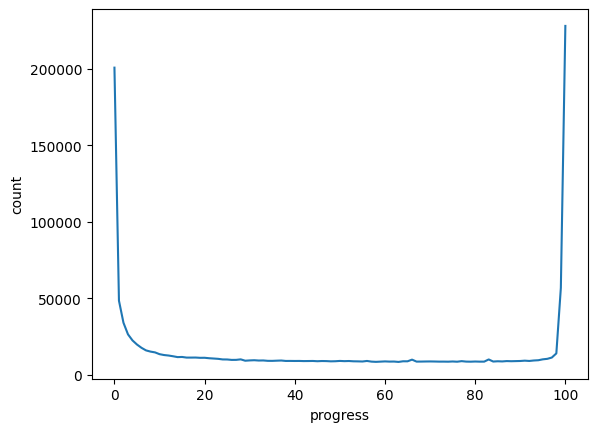

In [5]:
sns.lineplot(df['progress'].value_counts())

<Axes: xlabel='rating', ylabel='Count'>

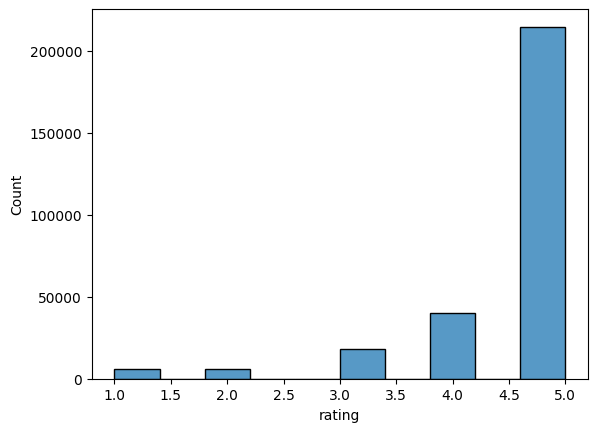

In [6]:
sns.histplot(df['rating'], bins = 10)

In [7]:
df['start_date'] = pd.to_datetime(df['start_date'])

In [36]:
df_implicit = df.copy()
df_explicit = df.dropna()

<Axes: xlabel='user_id', ylabel='Count'>

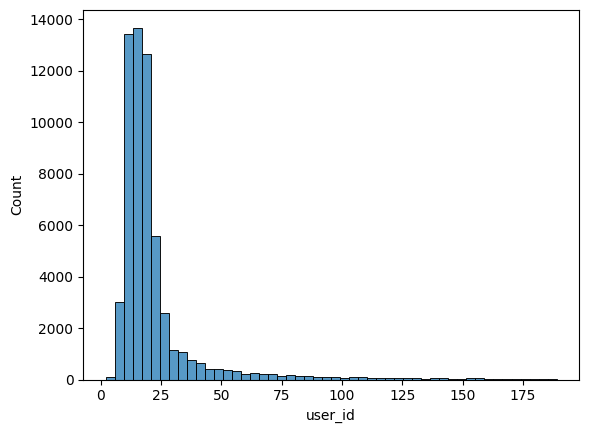

In [9]:
book_readers = df_implicit.groupby('item_id')['user_id'].count()
sns.histplot(book_readers[book_readers < book_readers.quantile(0.99)], bins=50)

<Axes: xlabel='item_id', ylabel='Count'>

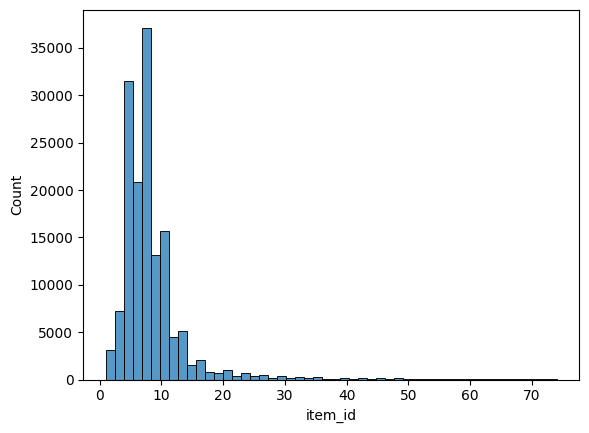

In [10]:
user_books = df_implicit.groupby('user_id')['item_id'].count()
sns.histplot(user_books[user_books < user_books.quantile(0.99)], bins=50)

In [37]:
def filter_positive_interactions(data:pd.DataFrame):
    
    rating = pd.to_numeric(data['rating'], errors='coerce')
    progress = pd.to_numeric(data['progress'], errors='coerce')

    mask = (rating >= 4.0) | (progress >= 50)

    return data[mask]

In [12]:
df_implicit_positive = filter_positive_interactions(df_implicit)

In [13]:
def filter_data(data: pd.DataFrame, min_book_readers=20, min_user_books=10):
    
    while True:
        old_len = data.shape[0]

        book_readers = data.groupby('item_id')['user_id'].count()
        valid_books = book_readers[book_readers >= min_book_readers].index
        data = data[data['item_id'].isin(valid_books)]

        user_books = data.groupby('user_id')['item_id'].count()
        valid_users = user_books[user_books >= min_user_books].index
        data = data[data['user_id'].isin(valid_users)]
        
        if old_len == data.shape[0]:
            break

    return data

In [14]:
df_implicit_positive = filter_data(df_implicit_positive)

In [15]:
df_implicit_positive

,user_id,item_id,progress,rating,start_date
29,137220,167814,99,NaN,2018-01-01
57,105213,249337,100,NaN,2018-01-01
92,46125,308861,100,4.0,2018-01-01
168,24438,185522,100,5.0,2018-01-01
196,125423,258438,99,5.0,2018-01-01
...,...,...,...,...,...
1532974,83403,97109,100,3.0,2019-12-31
1532976,74716,131294,99,5.0,2019-12-31
1533030,89522,32456,100,NaN,2019-12-31
1533058,80070,157666,100,3.0,2019-12-31


In [16]:
df_implicit_positive.info()

<class 'pandas.DataFrame'>
Index: 137716 entries, 29 to 1533061
Data columns (total 5 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     137716 non-null  int64         
 1   item_id     137716 non-null  int64         
 2   progress    137716 non-null  int64         
 3   rating      65434 non-null   float64       
 4   start_date  137716 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(3)
memory usage: 6.3 MB


In [17]:
def split_by_time(data:pd.DataFrame, test_size=0.2):

    data['start_date'] = pd.to_datetime(data['start_date'])

    # сначала группируем по пользователям, зачтем внутри группы по времени
    data = data.sort_values(['user_id', 'start_date']).reset_index(drop=True)
    
    ordered_readings = data.groupby('user_id').cumcount()

    group_size = data.groupby('user_id')['user_id'].transform('size')

    train_end = (group_size * (1 - test_size)).astype(int)

    mask = ordered_readings < train_end

    train = data[mask]
    test = data[~mask]

    return train, test

In [18]:
train, test = split_by_time(df_implicit_positive)
train, val = split_by_time(train, test_size=0.1)

In [19]:
train

,user_id,item_id,progress,rating,start_date
0,21,227272,100,NaN,2018-12-05
1,21,72618,100,NaN,2019-03-30
2,21,72356,100,NaN,2019-07-23
3,21,212027,99,NaN,2019-07-24
4,21,121640,100,5.0,2019-07-29
...,...,...,...,...,...
108676,159610,300766,97,NaN,2018-05-20
108677,159610,24677,98,NaN,2018-05-22
108678,159610,321015,96,NaN,2018-05-27
108679,159610,126070,100,NaN,2018-05-30


## User to User

Для реализации колоборативной фильтрации необходимо построить матрицу пользователь x книга.

За положительное взаимодействие будем считать что пользователь оставил хороший отзыв о книге или прочёл больше половины 

Также важно отметить, что мы не можем утверждать, что пользователям, провитавшим книгу на 10%, она не понравилась. Может они купили её или взяли прочитать в библиотеке. Но другого выхода нет, поскульку у нас нет возможности собрать всю информацию о пользователях 

In [20]:
from scipy.sparse import csr_matrix
from sklearn.base import BaseEstimator
from sklearn.neighbors import NearestNeighbors

In [21]:
class User2UserCF(BaseEstimator):

    def __init__(self, n_neighbors=30, user_col='user_id', item_col='item_id'):
        self.user_col = user_col
        self.item_col = item_col
        self.n_neighbors = n_neighbors

    def fit(self, X:pd.DataFrame, y=None):
        """Создаём матрицу взаимодействия пользователь х книга"""
        # Какие у нас есть пары уникальных взаимодействий
        interactions = X[[self.user_col, self.item_col]].dropna().drop_duplicates()
        
        # Задаёт обратное соотвествие 
        self.user_ids_ = interactions[self.user_col].unique()
        self.item_ids_ = interactions[self.item_col].unique()

        # Задаём сжатие индексов (прямое соотаветствие)
        self.user2idx = {user_id:idx for idx, user_id in enumerate(self.user_ids_)}
        self.item2idx = {item_id:idx for idx, item_id in enumerate(self.item_ids_)}

        # Переводим пары взаимодействия пользователь-объект в новые индексы
        rows = interactions[self.user_col].map(self.user2idx)
        cols = interactions[self.item_col].map(self.item2idx)

        self.matrix_ = csr_matrix(
            (np.ones(len(interactions)), (rows, cols)),
            shape=(len(self.user_ids_), len(self.item_ids_))
        )

        self.nn_ = NearestNeighbors(
            metric='cosine',
            algorithm='brute'
        )
        self.nn_.fit(self.matrix_)

        # Находим соседей сразу для всех пользователей (оптимизация)
        n_users = self.matrix_.shape[0]
        k = min(self.n_neighbors, n_users - 1)

        self.neighbor_distances_, self.neighbor_indexes_ = self.nn_.kneighbors(X=None, n_neighbors=k)

        return self
    
    def _get_neighbors(self, user_id):
        """Возвращает индексы соседей и их сходство с пользователем."""

        if user_id not in self.user_ids_:
            raise ValueError("Нет информации о пользователе")
        
        user_idx = self.user2idx[user_id]
        
        distances = self.neighbor_distances_[user_idx]
        indexes = self.neighbor_indexes_[user_idx]

        similarities = 1 - distances

        # Убираем нулевые сходства
        mask = similarities > 0

        return indexes[mask], similarities[mask]

    def similar_users(self, user_id):
        """Возвращает наиболее похожих пользователей."""
        indices, similarities = self._get_neighbors(user_id)

        return pd.DataFrame({
            self.user_col: self.user_ids_[indices],
            'similarity': similarities
        })
    
    def recommend(self, user_id, n_recommendations=10):
        """Рекомендует книги по взвешенным голосам соседей."""

        columns = [self.item_col, 'score']

        neighbor_indixes, similarities = self._get_neighbors(user_id)

        if len(neighbor_indixes) == 0:
            return pd.DataFrame(columns=columns)
        
        user_idx = self.user2idx[user_id]
        
        # Взвешиваем взаимодействия соседей по их сходству
        scores = (self.matrix_[neighbor_indixes].T @ similarities).ravel()

        # Не рекоммендуем книги, которые пользователь уже читал 
        seen = self.matrix_[user_idx].indices
        scores[seen] = -1

        # Получаем индексы книг, которые можно реккомендовать 
        candidates = np.flatnonzero(scores > 0)

        if len(candidates) == 0:
            return pd.DataFrame(columns=columns)

        # Сортируем книги по убыванию score
        order = np.argsort(scores[candidates])[::-1]
        top_indices = candidates[order[:n_recommendations]]

        return pd.DataFrame({
            self.item_col: self.item_ids_[top_indices],
            'score': scores[top_indices]
        })

In [22]:
CF = User2UserCF()

In [23]:
CF.fit(df_implicit_positive)

,n_neighbors,30
,user_col,'user_id'
,item_col,'item_id'


In [24]:
user = 137220
ans = CF.recommend(user)

In [25]:
ans

,item_id,score
0,148773,4.563744
1,131868,2.442802
2,99102,2.406241
3,110009,2.338907
4,180275,2.338907
5,2519,2.338907
6,155728,2.160539
7,196238,2.142009
8,233047,2.104681
9,148399,2.098242


## Оценка качества моделей

**Precision@K** - какая доля рекомендованных книг оказалась релевантной?

**Recall@K** - какую долю всех релевантных книг мы нашли в топ-K?

По качеству порядка релевантных книг:

**Average Precision (AP@K)** оценивает Precision в тех позициях списка, где встретилась релевантная книга.

**MAP@K** — среднее значение AP@K по всем оцениваемым пользователям:

**NDCG@K** - главное чтобы в начале списка стояли более релевантные книги

In [26]:
def evaluate_user2user(model, train:pd.DataFrame, test:pd.DataFrame, k=10):

    user_col = model.user_col
    item_col = model.item_col

    # Уникальные пары пользователь книга
    train_pairs = train[[user_col, item_col]].dropna().drop_duplicates().assign(_seen=True)
    test_pairs = test[[user_col, item_col]].dropna().drop_duplicates()

    # Исключаем книги, которые уже встретились в train 
    test_pairs = test_pairs.merge(train_pairs, how='left', on=[user_col, item_col])
    test_pairs = test_pairs[test_pairs['_seen'].isna()][[user_col, item_col]]

    # Релевантные книги для каждого пользователя 
    relevant_by_user = test_pairs.groupby(user_col)[item_col].apply(set).to_dict()

    results = []

    for user_id, relevant_items in relevant_by_user.items():

        recommended = model.recommend(user_id, k)[item_col].tolist()

        # Релевантность каждой книги в порядке выдачи: 0 или 1
        rel = np.array(
            [int(item in relevant_items) for item in recommended]
        )

        hits = np.sum(rel)
        ranks = np.arange(1, len(rel) + 1)

        # Precision@k
        precision_k = hits / k 

        # Recall@k
        recall_k = hits / len(relevant_items) 
        
        # DCG@k
        dcg = np.sum(rel / np.log2(ranks + 1))

        # IDCG@K: идеальное ранжирование
        ideal_len = min(len(relevant_items), k)
        ideal_ranks = np.arange(1, ideal_len + 1)

        idcg = np.sum(1 / np.log2(ideal_ranks + 1))

        # NDCG@K
        ndcg = dcg / idcg 

        # AP@K
        if len(rel) > 0:
            precision_at_rank = np.cumsum(rel) / ranks

            ap = np.sum(precision_at_rank * rel) / min(len(relevant_items), k)
        else:
            ap = 0.0

        results.append({
            'user_id': user_id,
            f'Precision@{k}': precision_k,
            f'Recall@{k}': recall_k,
            f'DCG@{k}': dcg,
            f'IDCG@{k}': idcg,
            f'NDCG@{k}': ndcg,
            f'AP@{k}': ap
        })

    per_user = pd.DataFrame(results)

    # Усредняем метрики по пользователям
    metrics = per_user.drop(columns='user_id').mean()

    return metrics, per_user

In [27]:
CF = User2UserCF(n_neighbors=30)
CF.fit(train)

metrics, per_user = evaluate_user2user(model=CF, train=train, test=test, k=10)

print(metrics)

Precision@10    0.064055
Recall@10       0.134041
DCG@10          0.305829
IDCG@10         3.088069
NDCG@10         0.108515
AP@10           0.062268
dtype: float64


In [28]:
neighbor_values = [10, 20, 30, 50, 100]

results = []

for n in neighbor_values:
    model = User2UserCF(n_neighbors=n)
    model.fit(train)

    metrics, _ = evaluate_user2user(
        model=model,
        train=train,
        test=val,
        k=10
    )

    results.append({
        'n_neighbors': n,
        **metrics.to_dict()
    })

comparison = pd.DataFrame(results).sort_values(
    'NDCG@10',
    ascending=False
)

comparison

,n_neighbors,Precision@10,Recall@10,DCG@10,IDCG@10,NDCG@10,AP@10
4,100,0.053285,0.240321,0.285755,2.013653,0.165570,0.118697
3,50,0.052289,0.238435,0.283144,2.013653,0.164622,0.118472
2,30,0.052019,0.237013,0.282785,2.013653,0.164037,0.118143
1,20,0.051185,0.233485,0.277864,2.013653,0.162089,0.117167
0,10,0.046607,0.212698,0.260879,2.013653,0.152756,0.111867


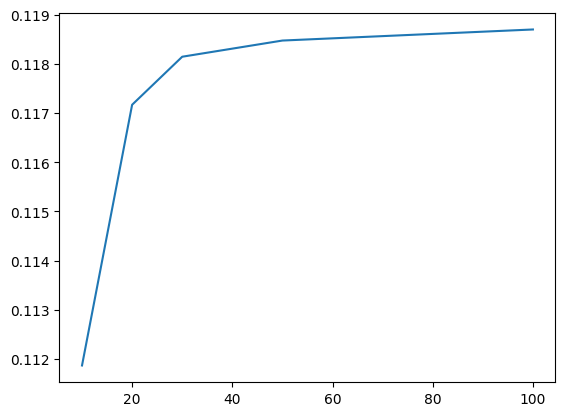

In [29]:
plt.plot(comparison['n_neighbors'], comparison['AP@10'])

In [30]:
CF = User2UserCF(n_neighbors=50)
CF.fit(train)

metrics, per_user = evaluate_user2user(model=CF, train=train, test=test, k=10)

print(metrics)

Precision@10    0.064674
Recall@10       0.135783
DCG@10          0.309179
IDCG@10         3.088069
NDCG@10         0.109839
AP@10           0.063037
dtype: float64


## Implicit ALS

**ALS (Alternating Least Squares)** — это также алгоритм коллаборативной фильтрации, но его идея заключается в том, чтобы представить пользователей и книги в виде латентых векторов небольшой размерности и научиться подбирать эти векторы так, чтобы они отражали предпочтения пользователей, а векторы книг - их характеристики.
**Implicit ALS** может работать также с неявным фидбеком. Вместо использования только положительных взаимодействий, будем использовать все доступные.

In [31]:
from scipy.sparse import csr_matrix

In [43]:
def make_matrix(data:pd.DataFrame, user_col='user_id', item_col='item_id', progress_col='progress', rating_col='rating', user2idx=None, item2idx=None, use_weights=True):

    interactions = data[[user_col, item_col, progress_col, rating_col]].dropna(subset=[user_col, item_col])

    interactions[progress_col] = pd.to_numeric(interactions[progress_col], errors="coerce").clip(0, 100)
    interactions[rating_col] = pd.to_numeric(interactions[rating_col], errors="coerce").clip(1, 5)

    # Если одна пара встретилась несколько раз, берём максимальный прогресс и среднюю оценку
    interactions = interactions.groupby([user_col, item_col], as_index=False).agg({progress_col : 'max', rating_col : 'mean'})

    # Создаём отображения только по тренировочным данным 
    if user2idx is None:
        user_ids = interactions[user_col].unique()
        user2idx = {user_id : idx for idx, user_id in enumerate(user_ids)}

    if item2idx is None:
        item_ids = interactions[item_col].unique()
        item2idx = {item_id : idx for idx, item_id in enumerate(item_ids)}

    # Оставляем только пользователей и книги, известные по переданным отображениям
    interactions = interactions[interactions[user_col].isin(user2idx) & interactions[item_col].isin(item2idx)]

    rows = interactions[user_col].map(user2idx)
    cols = interactions[item_col].map(item2idx)

    if use_weights:
        progress = interactions[progress_col].fillna(0).to_numpy(dtype=np.float32) / 100.0
        rating = interactions[rating_col].to_numpy(dtype=np.float32)

        has_rating = ~np.isnan(rating)

        rating_scaled = np.zeros_like(rating)
        rating_scaled[has_rating] = (rating[has_rating] - 1.0) / 4.0

        # Если оценки нет, используем только прогресс.
        # Если оценка есть, объединяем оба сигнала.
        strength = progress.copy()
        strength[has_rating] = 0.3 * progress[has_rating] + 0.7 * rating_scaled[has_rating]

        # Защита от нулевых весов - необходима, чтобы не обнулялись сигналы
        values = np.clip(strength, 1e-3, 1.0).astype(np.float32)
    else:
        values = np.ones(len(interactions), dtype=np.float32)
    
    matrix = csr_matrix(
        (values, (rows, cols)),
        shape=(len(user2idx), len(item2idx))
    )

    return matrix, user2idx, item2idx

In [44]:
def remove_seen_interactions(train, test, user_col='user_id', item_col='item_id'):

    # Уникальные пары пользователь книга
    train_pairs = train[[user_col, item_col]].dropna().drop_duplicates().assign(_seen=True)
    test_full = test.dropna(subset=[user_col, item_col]).copy()

    # Исключаем книги, которые уже встретились в train 
    result = test_full.merge(train_pairs, how='left', on=[user_col, item_col], validate='many_to_one')

    # Убираем взаимодействия, уже присутствующие в train
    result = result[result['_seen'].isna()]

    # Удаляем технический столбец
    result = result.drop(columns='_seen')

    return result.reset_index(drop=True)

In [47]:
train, test = split_by_time(df_implicit)
train, val = split_by_time(train, test_size=0.1)

In [49]:
train_matrix, user2idx, item2idx = make_matrix(train)
val_pairs_cleaned = remove_seen_interactions(train, val)
val_matrix, _, _ = make_matrix(val_pairs_cleaned, user2idx=user2idx, item2idx=item2idx, use_weights=False)

In [50]:
val_pairs_cleaned

,user_id,item_id,progress,rating,start_date
0,0,7388,38,NaN,2019-04-21
1,1,193138,37,5.0,2018-07-03
2,2,196475,0,NaN,2019-06-04
3,3,207473,35,NaN,2019-01-04
4,4,1691,0,NaN,2019-05-13
...,...,...,...,...,...
190785,159610,111262,100,NaN,2018-07-05
190786,159610,311935,100,NaN,2018-07-07
190787,159610,122569,0,NaN,2018-07-08
190788,159611,99055,0,NaN,2019-07-26


In [42]:
from implicit.als import AlternatingLeastSquares
from implicit.evaluation import ndcg_at_k, mean_average_precision_at_k, precision_at_k

d:\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [51]:
als = AlternatingLeastSquares(factors=100, regularization=0.05, alpha=10, iterations = 70)

als.fit(train_matrix)

d:\Python313\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 4 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()
100%|██████████| 70/70 [03:37<00:00,  3.11s/it]


In [52]:
metrics = {
    "NDCG@10": ndcg_at_k(
        als, train_matrix, val_matrix, K=10
    ),
    "MAP@10": mean_average_precision_at_k(
        als, train_matrix, val_matrix, K=10
    ),
    "Precision@10": precision_at_k(
        als, train_matrix, val_matrix, K=10
    ),
}

print(metrics, sep='\n')

100%|██████████| 148453/148453 [02:12<00:00, 1123.93it/s]

{'NDCG@10': 0.01944157949366676, 'MAP@10': 0.014461290805630378, 'Precision@10': 0.0392855173934616}


Best: {'NDCG@10': 0.17441438730336817, 'MAP@10': 0.12128172877913158, 'Precision@10': 0.18775223723460255}